# Three-method regional MD profile comparison

This notebook reads Python-generated summaries for Native-Column, O2-FS, O2-Column, and O3-Coordinate on fsaverage. It performs no expensive profile generation.

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

OUTPUT_ROOT = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/results/"
    "three_method_regional_comparison_fsaverage_common30"
)
profiles = pd.read_csv(OUTPUT_ROOT / "regional_profiles_long.csv")
qc = pd.read_csv(OUTPUT_ROOT / "regional_profile_qc.csv")
metrics = pd.read_csv(OUTPUT_ROOT / "regional_method_metrics.csv")
summary = pd.read_csv(OUTPUT_ROOT / "regional_method_summary.csv")
depth_summary = pd.read_csv(
    OUTPUT_ROOT / "regional_depthwise_method_summary.csv"
)
print("Subjects:", profiles.subject_id.nunique())
print("Regions per hemisphere:", profiles.region.nunique())
print("Methods:", sorted(profiles.method.unique()))

Subjects: 30
Regions per hemisphere: 34
Methods: ['Native-Column', 'O2-Column', 'O2-FS', 'O3-Coordinate']


In [4]:
qc_summary = (
    qc.groupby(["method", "status"], as_index=False)
    .size()
    .rename(columns={"size": "n_region_units"})
)
display(qc_summary)
display(
    summary[
        [
            "method_a",
            "method_b",
            "region",
            "n_subjects",
            "pearson_median",
            "mae_median",
            "sNMAE_pct_median",
        ]
    ].head(20)
)

,method,status,n_region_units
0,Native-Column,complete,2040
1,O2-Column,complete,2040
2,O2-FS,complete,2040
3,O3-Coordinate,complete,2040


,method_a,method_b,region,n_subjects,pearson_median,mae_median,sNMAE_pct_median
0,O2-Column,Native-Column,bankssts,30,0.999571,0.000007,1.014355
1,O2-Column,Native-Column,caudalanteriorcingulate,30,0.998089,0.000013,1.696817
2,O2-Column,Native-Column,caudalmiddlefrontal,30,0.999810,0.000006,0.784234
3,O2-Column,Native-Column,cuneus,30,0.999849,0.000012,1.450859
4,O2-Column,Native-Column,entorhinal,30,0.993326,0.000020,2.935396
5,O2-Column,Native-Column,frontalpole,30,0.997276,0.000039,4.417311
6,O2-Column,Native-Column,fusiform,30,0.999864,0.000006,0.915624
7,O2-Column,Native-Column,inferiorparietal,30,0.999857,0.000004,0.628805
8,O2-Column,Native-Column,inferiortemporal,30,0.999373,0.000007,1.043391
9,O2-Column,Native-Column,insula,30,0.999636,0.000016,2.146633


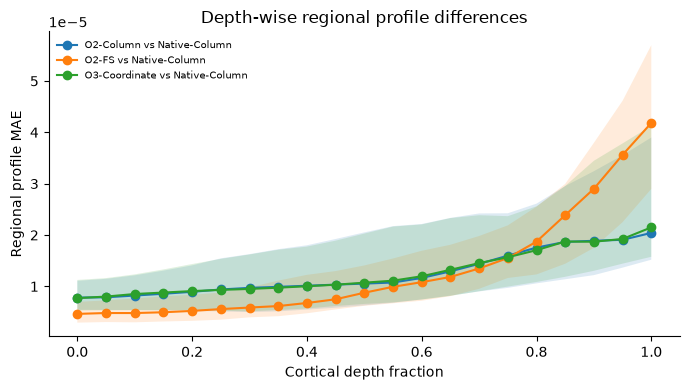

In [5]:
pair_labels = {
    ("O2-FS", "Native-Column"): "O2-FS vs Native-Column",
    ("O2-Column", "Native-Column"): "O2-Column vs Native-Column",
    ("O3-Coordinate", "Native-Column"): "O3-Coordinate vs Native-Column",
    ("O2-FS", "O3-Coordinate"): "O2-FS vs O3-Coordinate",
    ("O2-Column", "O3-Coordinate"): "O2-Column vs O3-Coordinate",
    ("O2-FS", "O2-Column"): "O2-FS vs O2-Column",
}
plot_data = depth_summary[
    depth_summary.method_b.eq("Native-Column")
].copy()
plot_data["comparison"] = [
    pair_labels[(a, b)]
    for a, b in zip(plot_data.method_a, plot_data.method_b)
]
depth_plot = (
    plot_data.groupby(["comparison", "depth_fraction"], as_index=False)
    .agg(mae_median=("mae", "median"),
         mae_q25=("mae", lambda x: x.quantile(0.25)),
         mae_q75=("mae", lambda x: x.quantile(0.75)))
)
fig, ax = plt.subplots(figsize=(7, 4))
for comparison, group in depth_plot.groupby("comparison"):
    group = group.sort_values("depth_fraction")
    ax.plot(group.depth_fraction, group.mae_median, marker="o", label=comparison)
    ax.fill_between(
        group.depth_fraction,
        group.mae_q25,
        group.mae_q75,
        alpha=0.15,
    )
ax.set_xlabel("Cortical depth fraction")
ax.set_ylabel("Regional profile MAE")
ax.set_title("Depth-wise regional profile differences")
ax.legend(frameon=False, fontsize=7)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

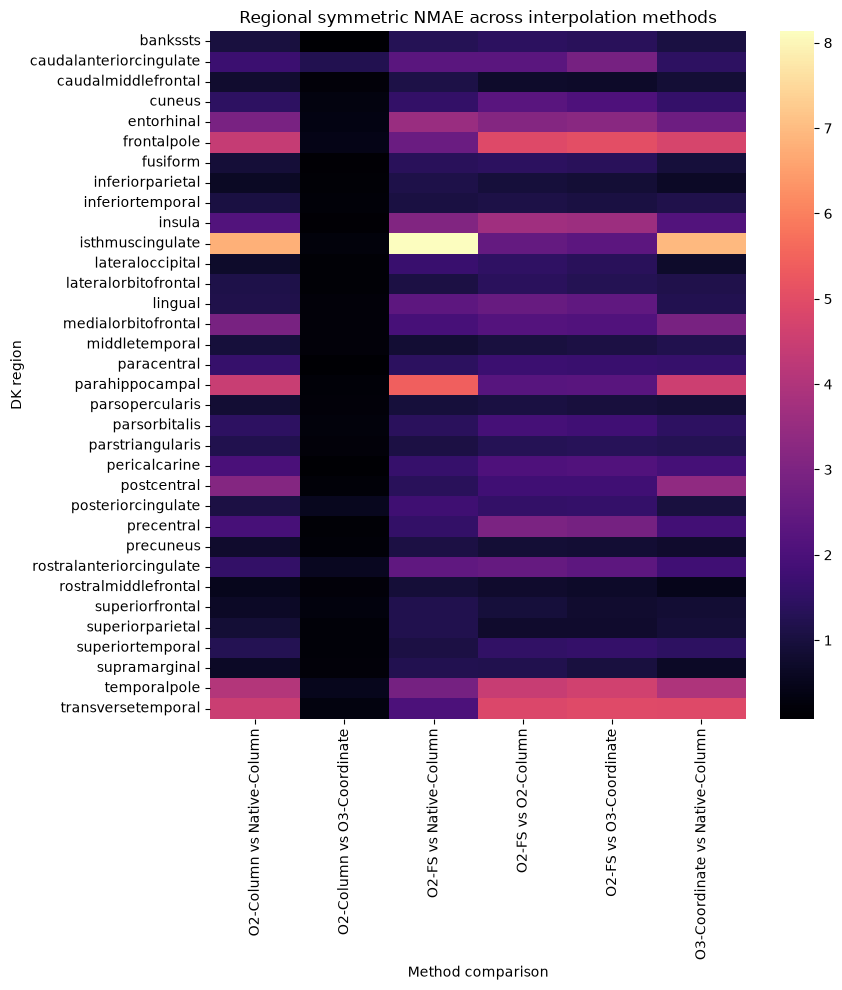

In [6]:
heatmap = summary.copy()
heatmap["comparison"] = [
    pair_labels[(a, b)]
    for a, b in zip(heatmap.method_a, heatmap.method_b)
]
heatmap = heatmap.pivot(
    index="region",
    columns="comparison",
    values="sNMAE_pct_median",
)
fig, ax = plt.subplots(figsize=(9, 10))
sns.heatmap(heatmap, cmap="magma", annot=False, ax=ax)
ax.set_title("Regional symmetric NMAE across interpolation methods")
ax.set_xlabel("Method comparison")
ax.set_ylabel("DK region")
fig.tight_layout()
plt.show()

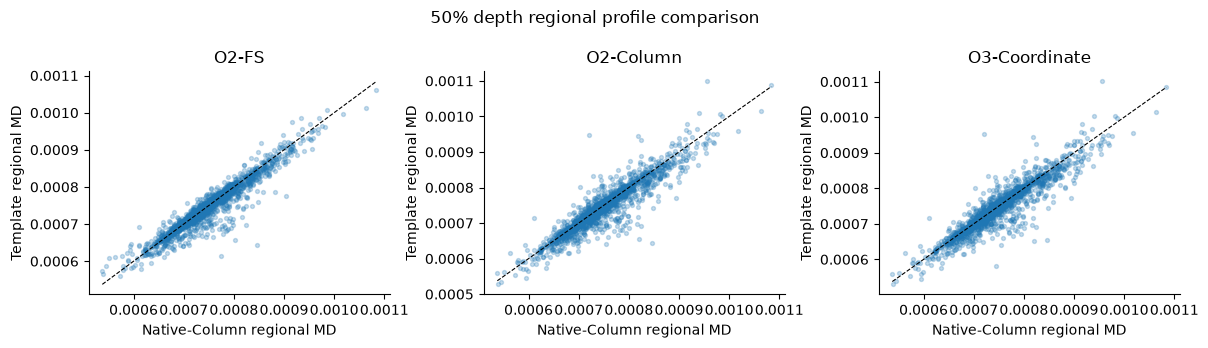

In [7]:
depth_50 = profiles[profiles.depth_fraction.eq(0.5)].copy()
depth_50 = depth_50.pivot_table(
    index=["subject_id", "hemisphere", "region"],
    columns="method",
    values="profile_value",
    aggfunc="first",
).reset_index()
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, method in zip(
    axes,
    ["O2-FS", "O2-Column", "O3-Coordinate"],
):
    ax.scatter(
        depth_50["Native-Column"],
        depth_50[method],
        s=8,
        alpha=0.25,
    )
    limits = [
        depth_50["Native-Column"].min(),
        depth_50["Native-Column"].max(),
    ]
    ax.plot(limits, limits, color="black", linestyle="--", linewidth=0.8)
    ax.set_title(method)
    ax.set_xlabel("Native-Column regional MD")
    ax.set_ylabel("Template regional MD")
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("50% depth regional profile comparison")
fig.tight_layout()
plt.show()